Homework 8, problem 3, part c

In [1]:
# libraries and parameters
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

rng = np.random.default_rng(42)

days = 30
hours_per_day = 24
T = days * hours_per_day  # 720 hours
lambda_max = 20

In [2]:
def true_rate(t):
    """True arrival rate, with t in hours after midnight."""
    return 12 + 8 * np.cos(np.pi * (t - 16) / 12)

In [3]:
# generate a HPPP at rate 20
n_proposed = rng.poisson(lambda_max * T)
proposed_times = np.sort(rng.uniform(0, T, n_proposed))

# probability lambda(t) / 20
keep_prob = true_rate(proposed_times) / lambda_max
keep = rng.random(n_proposed) < keep_prob
arrival_times = proposed_times[keep]

n_kept = len(arrival_times)

print("Proposed arrivals:", n_proposed)
print("Kept arrivals:", n_kept)
print("Fraction kept:", n_kept / n_proposed)

Proposed arrivals: 14502
Kept arrivals: 8767
Fraction kept: 0.6045373051992828
Theoretical fraction kept: 0.6
Theoretical expected arrivals: 8640


In [4]:
day_index = np.floor(arrival_times / 24).astype(int)
hour_index = np.floor(arrival_times % 24).astype(int)

# rows = days, columns = hours
hourly_counts = np.zeros((days, 24), dtype = int)
np.add.at(hourly_counts, (day_index, hour_index), 1)

mean_hourly_counts = hourly_counts.mean(axis=0)
hours = np.arange(24)

def integrated_rate(s, t):
    return (12 * (t - s) + (96 / np.pi) * (np.sin(np.pi * (t - 16) / 12) - np.sin(np.pi * (s - 16) / 12)))

expected_hourly_counts = np.array([integrated_rate(h, h + 1) for h in hours])

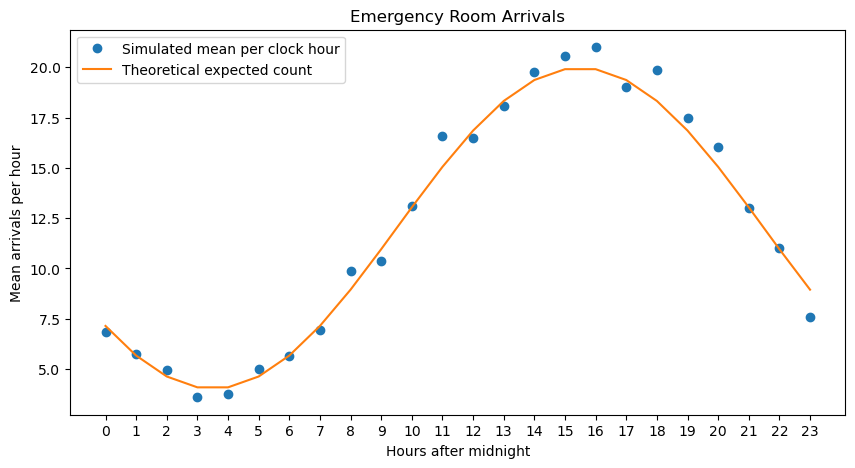

In [5]:
# plotting
plt.figure(figsize = (10, 5))
plt.plot(hours, mean_hourly_counts, "o", label = "Simulated mean per clock hour")
plt.plot(hours, expected_hourly_counts, "-", label = "Theoretical expected count")
plt.xticks(hours)
plt.xlabel("Hours after midnight")
plt.ylabel("Mean arrivals per hour")
plt.title("Emergency Room Arrivals")
plt.legend()
plt.show()

In [6]:
# mean and variance
early_morning = hourly_counts[:, 3]

print("Arrivals from 3 to 4am")
print("Simulated mean:", early_morning.mean())
print("Simulated variance:", early_morning.var(ddof = 1))
print("Theoretical Poisson mean and variance:", integrated_rate(3, 4))

Arrivals from 3 to 4am
Simulated mean: 3.6
Simulated variance: 4.524137931034482
Theoretical Poisson mean and variance: 4.091072564277042


In [8]:
def fitted_rate(t, a, b, phi):
    return a + b * np.cos(np.pi * (t - phi) / 12)

def negative_loglik(params):
    a, b, phi = params
    rates = fitted_rate(arrival_times, a, b, phi)

    if np.any(rates <= 0):
        return 1e100

    loglik = np.sum(np.log(rates)) - a * T
    return -loglik

# Require a > b >= 0 so the fitted rate remains positive.
constraints = [
    {"type": "ineq", 
     "fun": lambda p: p[0] - p[1] - 1e-6}
]

fit = minimize(
    negative_loglik,
    x0 = [10, 5, 14],
    method = "SLSQP",
    bounds = [(0.01, 40), (0, 39.99), (0, 24)],
    constraints = constraints,
    options = {"maxiter": 5000, "ftol": 1e-10}
)

a_hat, b_hat, phi_hat = fit.x
nhpp_loglik = -fit.fun

# Poisson MLE
n = len(arrival_times)
constant_rate = n / T
constant_loglik = n * np.log(constant_rate) - constant_rate * T

print("Maximum likelihood fit")
print("Optimization successful:", fit.success)
print("Estimated a:", a_hat)
print("Estimated b:", b_hat)
print("Estimated phi:", phi_hat)
print("True values: a=12, b=8, phi=16")
print("NHPP maximized log-likelihood:", nhpp_loglik)
print("Constant-rate MLE:", constant_rate)
print("Constant-rate log-likelihood:", constant_loglik)
print("Log-likelihood improvement:", nhpp_loglik - constant_loglik)

Maximum likelihood fit
Optimization successful: True
Estimated a: 12.176388211641619
Estimated b: 8.356297494926205
Estimated phi: 15.952060708078484
True values: a=12, b=8, phi=16
NHPP maximized log-likelihood: 14257.975159399824
Constant-rate MLE: 12.176388888888889
Constant-rate log-likelihood: 13146.105449884577
Log-likelihood improvement: 1111.8697095152475
